# 4.5 Graph networks

After an earthquake, ground shaking is measured only where there are seismic stations. Shaking maps such as the USGS ShakeMap fill in the region between the stations: they combine the recordings with a ground-motion model and with an amplification term for the ground under each location. That term matters. Soft sediments amplify shaking and rock does not, so the same earthquake shakes two nearby stations differently. Seismologists call a station's average amplification its **station term**. In this notebook's synthetic network the station terms span -0.29 to 0.30 in log10 PGA, a factor of 3.9 between the most and the least amplifying ground.

A seismic network is not a grid of pixels (4.3) or a sequence in time (4.4). Stations sit at irregular places, their number changes as instruments are installed or fail, and the order in which we list them means nothing. A **graph** describes that structure: stations are nodes, and edges join neighboring stations. A **graph network** computes the state of each station from the states of its neighbors, with the same weights at every station.

**Learning outcomes.** After this notebook you can:

1. describe a station network as a graph (node, edge, neighbor, adjacency, degree) and build its adjacency matrix;
2. compute one graph-convolution weighting and one message-passing update by hand;
3. train a fully connected network, a graph convolution network and a message-passing network on the same task, and rank them against interpolation and against floors computed from the known truth;
4. test what a graph network gives that a fully connected network does not (the station order does not matter, the network can grow) and say where it fails (stations without a history).

**From the literature.** Scarselli et al. (2009) defined the graph neural network model: each node's state is computed from its neighbors' states. Kipf & Welling (2017) made it cheap with the graph convolution of section 7, and Gilmer et al. (2017) wrote the general recipe of section 8, message passing. In seismology, van den Ende & Ampuero (2020) treated stations as nodes to estimate earthquake location and magnitude with any number of stations, in any order. Bloemheuvel et al. (2023) and Trappolini et al. (2025) predicted peak ground motion at the stations of the Italian network with graph convolutions, the second with stations masked as in this notebook. Schill & Bradley (2026) estimated shaking at sites without a recording in New Zealand and found the graph network "in line with the established multivariate normal conditional IM method". In atmospheric sciences, GraphCast (Lam et al., 2023) passes messages on a mesh around the globe. A warning comes from hydrology: Kirschstein & Sun (2024) gave a graph network the river network and found that its discharge forecasts did not benefit from it. A graph in the architecture is a hypothesis to test against a baseline, and this notebook tests it.

🖥️ [**Lecture slides: graph networks (lecture 23b)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec23b_graph_networks.html)

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import mlgeo_synth

# The networks in this notebook are tiny (a few thousand weights). On a CPU, one thread
# trains them fastest, and with one thread every sum is added in the same order, so a
# rerun reproduces every number to the last digit.
torch.set_num_threads(1)
N_LAYERS = 2        # layers of the graph networks (sections 7 and 8)
SEEDS = [0, 1, 2]   # each network is trained three times, from three random starting weights

## 1. Data: earthquakes recorded by a station network

We use a synthetic ground-motion data set from the course package `mlgeo_synth`, so that every term is known. `event_station_table` places 800 earthquakes in 20 sequences (clusters in space and time) over one year, in a 200 km by 200 km region recorded by 50 stations. Each recording is a peak ground acceleration (PGA, in g) given by a simple attenuation relation:

$$\log_{10}\mathrm{PGA} = 0.5\,M - 1.5\,\log_{10}(R + 10) - 1.0 + \delta_{\text{event}} + \delta_{\text{station}} + \varepsilon$$

- $M$ is the magnitude, between 3 and 6, and $R$ the distance from the epicenter, in km.
- The **event term** $\delta_{\text{event}}$ says that this earthquake shook more or less than the median for its magnitude (standard deviation 0.25).
- The **station term** $\delta_{\text{station}}$ is the ground under the station, the same for every earthquake (standard deviation 0.15).
- $\varepsilon$ is noise (standard deviation 0.1).

The coefficients are illustrative, not a published ground-motion model. We arrange the recordings as a matrix: one data sample per earthquake, one column per station.

In [2]:
df, truth = mlgeo_synth.event_station_table(n_events=800, n_stations=50, n_clusters=20, seed=0)
Y = df.pivot(index="event_id", columns="station_id", values="log10_pga").to_numpy()      # (earthquakes, stations)
dist = df.pivot(index="event_id", columns="station_id", values="dist_km").to_numpy()     # epicentral distance, km
xy = df.groupby("station_id")[["station_x_km", "station_y_km"]].first().to_numpy()       # station coordinates, km
events = df.groupby("event_id")[["cluster_id", "time_days", "magnitude", "event_x_km", "event_y_km"]].first()
print(f"{Y.shape[0]} earthquakes x {Y.shape[1]} stations; log10 PGA from {Y.min():.2f} to {Y.max():.2f}")
df.head()

800 earthquakes x 50 stations; log10 PGA from -3.80 to 1.05


,event_id,station_id,cluster_id,time_days,magnitude,event_x_km,event_y_km,station_x_km,station_y_km,dist_km,log10_pga
0,0,0,11,93.74369,5.23648,136.537965,132.84674,110.550164,106.005157,37.360894,-0.876633
1,0,1,11,93.74369,5.23648,136.537965,132.84674,157.174171,172.054265,44.306692,-1.246954
2,0,2,11,93.74369,5.23648,136.537965,132.84674,0.280663,92.619082,142.071520,-1.541429
3,0,3,11,93.74369,5.23648,136.537965,132.84674,136.853211,70.960810,61.886734,-1.440373
4,0,4,11,93.74369,5.23648,136.537965,132.84674,158.170728,1.432355,133.183021,-1.642666


Because the data are synthetic, we can split each recording into its known parts. What is left after removing the median attenuation and the event term is the station term plus noise; what is left after removing the station term too is noise only. Section 3 uses both as floors.

In [3]:
c = truth["coeffs"]
median = (c["a_mag"] * events["magnitude"].to_numpy()[:, None]
          + c["b_dist"] * np.log10(dist + c["c_km"]) + c["intercept"])
event_term = truth["event_terms"].to_numpy()[:, None]
station_term = truth["station_terms"].to_numpy()
station_plus_noise = Y - (median + event_term)                   # left if the earthquake were known exactly
noise_only = Y - (median + event_term + station_term[None, :])   # left if the station terms were known too
print(f"station terms: std {station_term.std(ddof=1):.3f}, from {station_term.min():.2f} to {station_term.max():.2f} (log10)")

station terms: std 0.150, from -0.29 to 0.30 (log10)


## 2. The task: shaking at stations without a recording

For each earthquake, we hide 20 to 30% of the stations, as if they had not recorded (a station down, a late telemetry packet, a clipped record), and predict log10 PGA at those stations from the stations that recorded the same earthquake. Magnitude and epicenter are **not** inputs: the network must infer the pattern of shaking from the recordings alone. One value is predicted per station: this is a **node-level** prediction. A **graph-level** prediction gives one value per earthquake, such as its magnitude (van den Ende & Ampuero, 2020).

Three choices define the test:

- **Split by earthquake sequence, in time.** Earthquakes of one sequence share a location, so their patterns of shaking look alike, and a random split by earthquake would put near-copies on both sides. We order the 20 sequences by their median time: the first 14 train, the next 3 validate, the last 3 test (train on the past, validate and test on the future).
- **Ten stations are "installed later".** The networks train on 40 stations. Section 11 adds the other 10.
- **New hidden stations at every epoch.** In training, each earthquake gets a new random set of hidden stations at every epoch, so the network cannot memorize which stations are missing. Validation and test use 4 fixed sets of hidden stations per earthquake.

In [4]:
cluster_time = events.groupby("cluster_id")["time_days"].median().sort_values()
order = cluster_time.index.to_numpy()                     # sequences from the earliest to the latest
clusters = {"train": order[:14], "validation": order[14:17], "test": order[17:]}
ev = {k: np.flatnonzero(events["cluster_id"].isin(v).to_numpy()) for k, v in clusters.items()}

rng = np.random.default_rng(100)
new = np.sort(rng.choice(50, 10, replace=False))          # 10 stations installed later (section 11)
old = np.setdiff1d(np.arange(50), new)                    # the 40-station network we train on
for k, v in ev.items():
    print(f"{k:10s} {len(clusters[k]):2d} sequences, {len(v):3d} earthquakes")
print("stations installed later:", new)

train      14 sequences, 565 earthquakes
validation  3 sequences, 115 earthquakes
test        3 sequences, 120 earthquakes
stations installed later: [ 2  3  5 13 20 26 28 31 35 48]


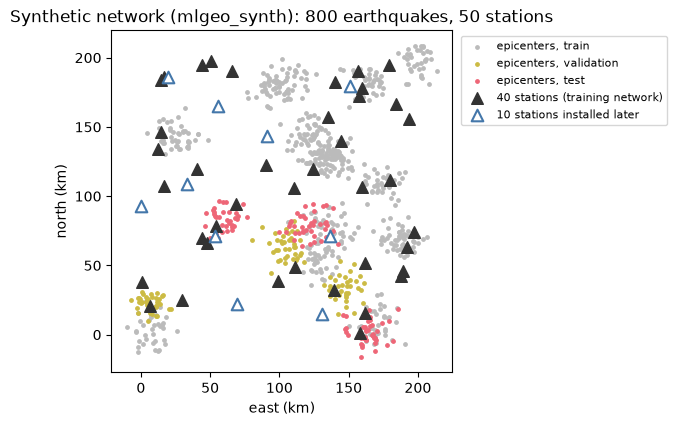

In [5]:
colors = {"train": "#BBBBBB", "validation": "#CCBB44", "test": "#EE6677"}
fig, ax = plt.subplots(figsize=(6, 5.5))
for k, idx in ev.items():
    ax.scatter(events["event_x_km"].iloc[idx], events["event_y_km"].iloc[idx], s=6,
               color=colors[k], label=f"epicenters, {k}")
ax.scatter(*xy[old].T, marker="^", s=70, color="#333333", label="40 stations (training network)")
ax.scatter(*xy[new].T, marker="^", s=70, facecolor="white", edgecolor="#4477AA", lw=1.5,
           label="10 stations installed later")
ax.set_xlabel("east (km)")
ax.set_ylabel("north (km)")
ax.set_aspect("equal")
ax.set_title("Synthetic network (mlgeo_synth): 800 earthquakes, 50 stations")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Each station carries two numbers into the network: its standardized log10 PGA (set to 0 where the station is hidden) and a mask flag (1 where hidden, 0 where recorded). The flag tells the network that a 0 means "no recording", not "average shaking". The mean and standard deviation for the standardization come from the training earthquakes only.

In [6]:
def draw_masks(rng, n_samples, n_stations, lo=0.2, hi=0.3):
    """Boolean (n_samples, n_stations): True = this station is hidden for this data sample."""
    n_masked = rng.integers(int(np.ceil(lo * n_stations)), int(np.floor(hi * n_stations)) + 1, n_samples)
    rank = rng.random((n_samples, n_stations)).argsort(1).argsort(1)   # a random order of the stations
    return rank < n_masked[:, None]


mu, sd = float(Y[ev["train"]][:, old].mean()), float(Y[ev["train"]][:, old].std())
z = (Y - mu) / sd                                         # standardized with training values only


def node_inputs(z, mask):
    """(data samples, stations, 2): standardized log10 PGA (0 where hidden) and the mask flag."""
    return torch.tensor(np.stack([np.where(mask, 0.0, z), mask.astype(float)], -1), dtype=torch.float32)


rng_eval = np.random.default_rng(7)
va, te = np.repeat(ev["validation"], 4), np.repeat(ev["test"], 4)   # 4 sets of hidden stations per earthquake
m_va, m_te = draw_masks(rng_eval, len(va), 40), draw_masks(rng_eval, len(te), 40)
X_va, X_te = node_inputs(z[va][:, old], m_va), node_inputs(z[te][:, old], m_te)
y_te = Y[te][:, old]
print(f"validation: {len(va)} data samples; test: {len(te)} data samples, {m_te.sum()} hidden values")
print("first test data sample, first 4 stations (value, mask flag):")
print(X_te[0, :4].numpy().round(2))

validation: 460 data samples; test: 480 data samples, 4786 hidden values
first test data sample, first 4 stations (value, mask flag):
[[1.76 0.  ]
 [0.26 0.  ]
 [0.4  0.  ]
 [0.36 0.  ]]


## 3. Baselines first

Two methods that need no training, and two floors that only the known truth can give:

- **Mean of recorded stations**: the same value at every hidden station.
- **Inverse-distance weighting (IDW)**: at each hidden station, the average of the recorded stations weighted by 1/distance². This is the classic spatial interpolation.
- **Floor 1, station term + noise**: if we knew the median attenuation and the event term exactly, the error left at a station would be its station term plus noise. A method that knows nothing about the individual stations cannot do better on average.
- **Floor 2, noise only**: if we also knew every station term, only the noise would be left.

The metric is the mean absolute error (MAE) over the hidden stations, in log10 PGA. Read it also as a factor: an MAE of 0.15 means a typical prediction off by a factor of 10^0.15 = 1.41.

In [7]:
def mae(pred, y, mask):
    """Mean absolute error over the hidden stations, in log10 PGA."""
    return float(np.abs(pred - y)[mask].mean())


def mean_of_recorded(y, mask):
    m = np.where(mask, 0.0, y).sum(1) / (~mask).sum(1)
    return np.repeat(m[:, None], y.shape[1], 1)


def idw(y, mask, xy, power=2.0):
    """Inverse-distance weighting from the recorded stations of each data sample."""
    D = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
    pred = np.empty_like(y)
    for s in range(len(y)):
        w = np.where(mask[s][None, :], 0.0, 1.0 / np.maximum(D, 1e-9) ** power)   # hidden stations get no weight
        np.fill_diagonal(w, 0.0)
        pred[s] = w @ np.where(mask[s], 0.0, y[s]) / w.sum(1)
    return pred


rf_te = station_plus_noise[te][:, old]
baselines = {
    "mean of recorded stations": mean_of_recorded(y_te, m_te),
    "inverse-distance weighting": idw(y_te, m_te, xy[old]),
}
floors = {
    "floor: station term + noise left": np.abs(rf_te)[m_te].mean(),
    "floor: noise only left": np.abs(noise_only[te][:, old])[m_te].mean(),
}
for name, p in baselines.items():
    print(f"{name:34s} MAE {mae(p, y_te, m_te):.3f}  factor {10 ** mae(p, y_te, m_te):.2f}")
for name, v in floors.items():
    print(f"{name:34s} MAE {v:.3f}  factor {10 ** v:.2f}")

mean of recorded stations          MAE 0.306  factor 2.02
inverse-distance weighting         MAE 0.182  factor 1.52
floor: station term + noise left   MAE 0.138  factor 1.38
floor: noise only left             MAE 0.080  factor 1.20


IDW reaches 0.182 (a factor of 1.52), against 0.306 for the mean of recorded stations. The gap between IDW and floor 1 (0.138) is what a method could still gain by knowing the earthquake: its magnitude, location and event term. The gap between floor 1 and floor 2 (0.080) is what it could gain by knowing each station's term. Keep both gaps in mind for the leaderboard.

## 4. One training loop, one metric

All three networks share one training loop, the loop of the training block (section [4.7](mlgeo_4.7_ModelTraining.ipynb)):

- **Starting weights** are random numbers drawn after `torch.manual_seed(seed)`, for seeds 0, 1 and 2, never zeros, so that the neurons of a layer receive different gradients and learn different things (4.2). Each network is trained three times, and the leaderboard reports the mean and the sample standard deviation of the three test MAEs.
- **Loss**: for each hidden station of a data sample, the squared error between prediction and observation (in standardized units); the loss of a batch is the mean over all hidden stations of the batch. Recorded stations are given as inputs, so they do not count.
- **Optimizer**: Adam, learning rate $\alpha = 10^{-3}$, batches of 32 earthquakes, new hidden stations at every epoch.
- **Early stopping**: after each epoch we compute the loss on the validation earthquakes. Training stops when it has not improved for 20 epochs (at most 200 epochs), and we keep the weights of the best epoch.

In [8]:
def n_weights(model):
    return sum(p.numel() for p in model.parameters())


def predict(model, X, g):
    """Predictions in log10 PGA for inputs X on graph g (g is ignored by the fully connected network)."""
    model.eval()
    with torch.no_grad():
        return model(X, g).numpy() * sd + mu


def masked_mse(pred, obs, mask):
    """Mean of the squared errors over the hidden stations of a batch."""
    return ((pred - obs) ** 2 * mask).sum() / mask.sum()


z_tr = torch.tensor(z[ev["train"]][:, old], dtype=torch.float32)
z_va, mva_t = torch.tensor(z[va][:, old], dtype=torch.float32), torch.tensor(m_va, dtype=torch.float32)


def train(model, g, seed, max_epochs=200, patience=20, lr=1e-3, batch_size=32):
    rng = np.random.default_rng(seed + 1000)              # hidden stations and batch order
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(z_tr)
    best, best_state, bad, history = np.inf, None, 0, {"train": [], "validation": []}
    t0 = time.time()
    for epoch in range(max_epochs):
        mask = draw_masks(rng, n, 40)                     # new hidden stations at every epoch
        X, M = node_inputs(z_tr.numpy(), mask), torch.tensor(mask, dtype=torch.float32)
        order = rng.permutation(n)
        model.train()
        total = 0.0
        for j in range(0, n, batch_size):
            idx = order[j:j + batch_size]
            loss = masked_mse(model(X[idx], g), z_tr[idx], M[idx])   # mean loss over the batch
            opt.zero_grad()
            loss.backward()                               # gradient of the loss for every weight
            opt.step()                                    # update
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = masked_mse(model(X_va, g), z_va, mva_t).item()
        history["train"].append(total / n)
        history["validation"].append(val_loss)
        if val_loss < best - 1e-5:
            best, bad = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad == patience:
                break
    model.load_state_dict(best_state)                     # keep the best epoch
    return dict(time_s=time.time() - t0, epochs=epoch + 1,
                best_epoch=int(np.argmin(history["validation"])) + 1, history=history)


results = {}


def run(name, make_model, g):
    """Train one kind of network from each seed; keep the models and their test predictions."""
    for seed in SEEDS:
        torch.manual_seed(seed)                           # random starting weights, recorded seed
        model = make_model()
        info = train(model, g, seed)
        pred = predict(model, X_te, g)
        results.setdefault(name, []).append(dict(seed=seed, model=model, pred=pred, weights=n_weights(model), **info,
                                                 mae=mae(pred, y_te, m_te)))
        print(f"{name}, seed {seed}: test MAE {results[name][-1]['mae']:.3f} after {info['epochs']} epochs "
              f"({info['time_s']:.0f} s)")

## 5. A fully connected network on the whole network

The first network ignores geography. It flattens the 40 stations × 2 numbers into 80 inputs, passes them through two hidden layers of 128 neurons (4.1, 4.2) and returns 40 predictions, one per station. Station number 7 is always inputs 14 and 15 and prediction 7: the network learns what each position means.

In [9]:
class FullyConnected(torch.nn.Module):
    def __init__(self, n_stations=40, hidden=128):
        super().__init__()
        self.n_stations = n_stations
        self.net = torch.nn.Sequential(
            torch.nn.Linear(2 * n_stations, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, n_stations))

    def forward(self, x, g=None):                  # x: (batch, stations, 2); the graph g is not used
        if x.shape[1] != self.n_stations:
            raise ValueError(f"built for {self.n_stations} stations, got {x.shape[1]}")
        return self.net(x.flatten(1))              # (batch, 80) -> (batch, 40)


run("fully connected", FullyConnected, None)

fully connected, seed 0: test MAE 0.137 after 132 epochs (1 s)


fully connected, seed 1: test MAE 0.137 after 114 epochs (1 s)


fully connected, seed 2: test MAE 0.136 after 192 epochs (2 s)


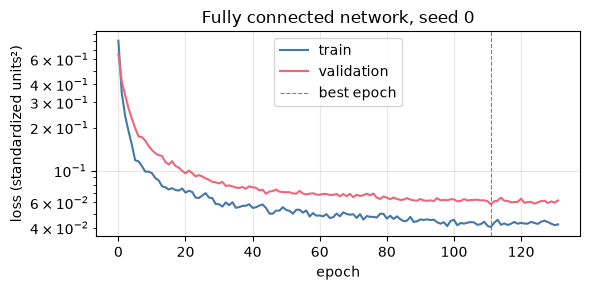

In [10]:
hist = results["fully connected"][0]["history"]
plt.figure(figsize=(6, 3))
plt.plot(hist["train"], color="#4477AA", label="train")
plt.plot(hist["validation"], color="#EE6677", label="validation")
plt.axvline(results["fully connected"][0]["best_epoch"] - 1, color="gray", ls="--", lw=0.8, label="best epoch")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("loss (standardized units²)")
plt.title("Fully connected network, seed 0")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The fully connected network reaches a test MAE of 0.136 ± 0.001 over the three seeds, far better than IDW (0.182) and slightly below floor 1 (0.138). A method below floor 1 must know something about the individual stations: section 9 shows that it has learned their station terms. It uses 32,040 weights. Keep two weaknesses in mind for sections 10 and 11: it depends on the order in which the stations are listed, and its first layer has exactly 80 inputs.

## 6. The station network as a graph

| term | meaning | in this notebook |
|---|---|---|
| node | an object of the graph | a station |
| edge | a link between two nodes | two stations among each other's 6 nearest |
| neighbors of a node | the nodes joined to it by an edge | the nearby stations |
| adjacency matrix $A$ | $A_{ij} = 1$ if nodes $i$ and $j$ are joined, else 0 | 40 × 40, symmetric |
| degree | the number of neighbors of a node | 6 to 10 |
| node features | numbers carried by each node | value and mask flag |
| edge features | numbers carried by each edge | distance, east and north offsets |
| message | what a neighbor sends to a node | section 8 |
| aggregation | how a node combines its messages, the same way for any number of neighbors | mean |
| node-level / graph-level prediction | one value per node / one value per graph | per station (this notebook) / per earthquake |

**Who is a neighbor?** We join each station to its $k = 6$ nearest stations. That relation is not symmetric (station $j$ can be among the 6 nearest of $i$ without $i$ being among the 6 nearest of $j$), so we keep an edge when either station chose the other. Every station then has at least 6 neighbors.

**Normalized adjacency.** Kipf & Welling (2017) average each station with its neighbors using

$$\hat A = \tilde D^{-1/2}\,(A + I)\,\tilde D^{-1/2}, \qquad \hat A_{ij} = \frac{1}{\sqrt{\tilde d_i\,\tilde d_j}} \text{ if } i \text{ and } j \text{ are joined or } i = j,$$

where $I$ adds a self-loop (a station keeps its own value) and $\tilde d_i$ is the degree of station $i$ counting itself. It is a normalized average, including the node itself, in which a neighbor with many neighbors weighs less.

### Your turn (1): the adjacency of five stations

Five stations, each joined to its **2** nearest stations (6 is too many for 5 stations). The cell gives the distances and the two nearest stations of each station. Fill the adjacency matrix `A5`, make it symmetric, then compute the normalized adjacency `A5_hat`.

Hint: a `for` loop over the 5 stations with `A5[i, nn5[i]] = 1`, then `np.maximum(A5, A5.T)`, `np.eye(5)`, `.sum(1)` and `np.sqrt`. About six lines.

In [11]:
xy5 = np.array([[0.0, 0.0], [10.0, 0.0], [0.0, 10.0], [30.0, 5.0], [40.0, 0.0]])     # km
D5 = np.hypot(xy5[:, None, 0] - xy5[None, :, 0], xy5[:, None, 1] - xy5[None, :, 1])   # distances, km
nn5 = np.argsort(D5 + np.diag(np.full(5, np.inf)), axis=1)[:, :2]                     # 2 nearest of each station
print("2 nearest stations of each station:", nn5.tolist())

A5 = np.zeros((5, 5))
# your code: A5[i, j] = 1 for the 2 nearest j of each station i, then make A5 symmetric
A5_hat = None   # your code: add the identity, compute the degrees, normalize

2 nearest stations of each station: [[1, 2], [0, 2], [0, 1], [4, 1], [3, 1]]


*Answer below (click to open it).*

In [12]:
A5 = np.zeros((5, 5))
for i in range(5):
    A5[i, nn5[i]] = 1
A5 = np.maximum(A5, A5.T)                     # an edge goes both ways
A5_tilde = A5 + np.eye(5)                     # each station also keeps its own value
deg5 = A5_tilde.sum(1)                        # degrees, counting the station itself
A5_hat = A5_tilde / np.sqrt(deg5[:, None] * deg5[None, :])
print("A =\n", A5.astype(int))
print("degrees with self-loop:", deg5)
print("normalized adjacency =\n", A5_hat.round(3))

A =
 [[0 1 1 0 0]
 [1 0 1 1 1]
 [1 1 0 0 0]
 [0 1 0 0 1]
 [0 1 0 1 0]]
degrees with self-loop: [3. 5. 3. 3. 3.]
normalized adjacency =
 [[0.333 0.258 0.333 0.    0.   ]
 [0.258 0.2   0.258 0.258 0.258]
 [0.333 0.258 0.333 0.    0.   ]
 [0.    0.258 0.    0.333 0.333]
 [0.    0.258 0.    0.333 0.333]]


Station 1 chose stations 0 and 2, but stations 3 and 4 chose station 1 too, so after symmetrizing it has 4 neighbors (degree 5 with itself). Its weight for station 3 is $1/\sqrt{5 \times 3} = 0.258$. Each row of $\hat A$ is a set of averaging weights over a station and its neighbors.

The same lines build the graph of the 40-station network. The function also returns the **edge list**: for each directed edge, the station that sends (`src`), the edge features (distance, east offset, north offset, divided by 50 km), and a matrix `S` used in section 8 to average the messages arriving at each station.

In [13]:
def build_graph(xy, k=6, scale_km=50.0):
    """k-nearest-neighbor graph of the stations at coordinates xy (km)."""
    n = len(xy)
    D = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
    nn = np.argsort(D + np.diag(np.full(n, np.inf)), axis=1)[:, :k]
    A = np.zeros((n, n))
    A[np.repeat(np.arange(n), k), nn.ravel()] = 1
    A = np.maximum(A, A.T)
    A_tilde = A + np.eye(n)
    deg = A_tilde.sum(1)
    A_hat = A_tilde / np.sqrt(deg[:, None] * deg[None, :])
    dst, src = np.nonzero(A)                                  # edge e: station src[e] sends to station dst[e]
    edge = np.stack([D[dst, src], xy[src, 0] - xy[dst, 0], xy[src, 1] - xy[dst, 1]], 1) / scale_km
    S = np.zeros((n, len(src)))
    S[dst, np.arange(len(src))] = 1.0 / A.sum(1)[dst]         # row i averages the edges arriving at station i
    f = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(A=A, A_hat=f(A_hat), src=torch.from_numpy(src), edge=f(edge), S=f(S),
                n_edges=len(src), degree=A.sum(1))


g_old = build_graph(xy[old])
print(f"40 stations, {g_old['n_edges']} directed edges ({g_old['n_edges'] // 2} station pairs), "
      f"degree {g_old['degree'].min():.0f} to {g_old['degree'].max():.0f}, mean {g_old['degree'].mean():.1f}")

40 stations, 284 directed edges (142 station pairs), degree 6 to 10, mean 7.1


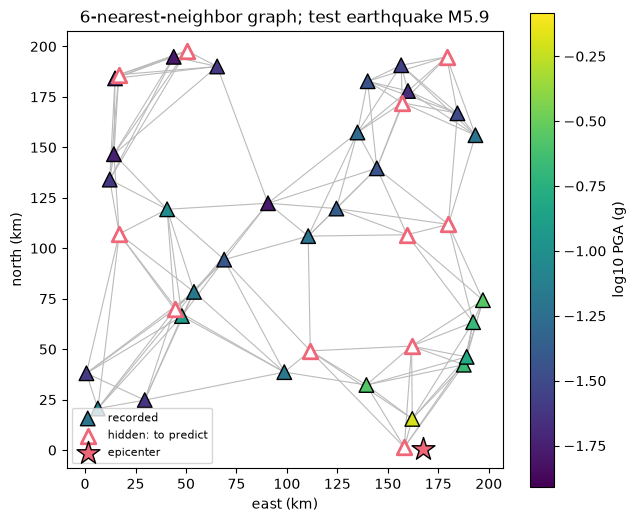

In [14]:
e_show = ev["test"][np.argmax(events["magnitude"].to_numpy()[ev["test"]])]   # largest test earthquake
s_show = np.flatnonzero(te == e_show)[0]                                     # its first set of hidden stations
pts, hid = xy[old], m_te[s_show]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for i, j in zip(*np.nonzero(np.triu(g_old["A"]))):
    ax.plot(*pts[[i, j]].T, color="#BBBBBB", lw=0.8, zorder=1)
sc = ax.scatter(*pts[~hid].T, c=y_te[s_show, ~hid], cmap="viridis", vmin=y_te[s_show].min(),
                vmax=y_te[s_show].max(), marker="^", s=110, edgecolor="k", zorder=3, label="recorded")
ax.scatter(*pts[hid].T, marker="^", s=110, facecolor="white", edgecolor="#EE6677", lw=2, zorder=3,
           label="hidden: to predict")
ax.scatter(events.loc[e_show, "event_x_km"], events.loc[e_show, "event_y_km"], marker="*", s=300,
           color="#EE6677", edgecolor="k", zorder=4, label="epicenter")
plt.colorbar(sc, label="log10 PGA (g)")
ax.set_xlabel("east (km)")
ax.set_ylabel("north (km)")
ax.set_aspect("equal")
ax.set_title(f"6-nearest-neighbor graph; test earthquake M{events.loc[e_show, 'magnitude']:.1f}")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 7. Graph convolution

A graph convolution layer (Kipf & Welling, 2017) multiplies each station's numbers by one weight matrix $W$, shared by all stations, then takes the normalized average over the station and its neighbors:

$$H' = \mathrm{ReLU}\big(\hat A\, H\, W\big)$$

$H$ holds one row of numbers per station (2 numbers at the input, 32 after the first layer). After two layers, each station has heard from its neighbors and from their neighbors. A final linear layer turns each station's 32 numbers into one prediction. The convolution of 4.3 is the same operation on a regular grid of pixels.

What this layer cannot do: $\hat A$ says who is a neighbor, not how far away or in which direction, and the weights are the same at every station. Two stations with similar neighborhoods are treated alike.

In [15]:
class GraphConv(torch.nn.Module):
    def __init__(self, n_layers=N_LAYERS, hidden=32):
        super().__init__()
        dims = [2] + [hidden] * n_layers
        self.layers = torch.nn.ModuleList(torch.nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.head = torch.nn.Linear(hidden, 1)

    def forward(self, x, g):                       # x: (batch, stations, 2)
        h = x
        for layer in self.layers:
            h = torch.relu(g["A_hat"] @ layer(h))  # same W at every station, then average over neighbors
        return self.head(h).squeeze(-1)            # (batch, stations)


run("graph convolution", GraphConv, g_old)

graph convolution, seed 0: test MAE 0.187 after 104 epochs (2 s)


graph convolution, seed 1: test MAE 0.187 after 95 epochs (2 s)


graph convolution, seed 2: test MAE 0.187 after 153 epochs (4 s)


The graph convolution reaches 0.187 ± 0.000: slightly worse than IDW (0.182), with 1,185 weights. It has learned a smoother on the graph, and IDW is already a good smoother.

## 8. Message passing with edge features

Gilmer et al. (2017) wrote most graph networks as one recipe in three steps. For station $i$ and each neighbor $j$:

1. **Message**: $m_{ij} = \mathrm{ReLU}\big(W_m\,[\,h_j,\ d_{ij},\ \Delta x_{ij},\ \Delta y_{ij}\,] + b_m\big)$. The neighbor's numbers $h_j$ are joined with the edge features: its distance $d_{ij}$ and its east and north offsets $\Delta x_{ij}$, $\Delta y_{ij}$ (in units of 50 km).
2. **Aggregation**: $a_i = \mathrm{mean}_j\, m_{ij}$, the mean of the messages over the neighbors. A mean works for any number of neighbors.
3. **Update**: $h_i' = \mathrm{ReLU}\big(W_u\,[\,h_i,\ a_i\,] + b_u\big)$. The station keeps its own numbers next to the mean of the messages.

The weights $W_m$ and $W_u$ are the same at every station. Unlike the graph convolution, the message depends on how far away and in which direction the neighbor is.

### Your turn (2): one message-passing update by hand

Station $i$ is hidden: $h_i = [0, 1]$ (value 0, mask flag 1). Its three neighbors recorded standardized values 0.8, 0.2 and −0.6. The weights below are set by hand (biases are 0). Compute the three messages, their mean, and the new state of station $i$.

Hint: `np.concatenate([h_nb, e], axis=1)` joins each neighbor's numbers with its edge features; `@ W_m.T`, `np.maximum(0, ...)` and `.mean(axis=0)` do the rest. Three lines.

In [16]:
h_i = np.array([0.0, 1.0])                                # station i: hidden (value 0, mask flag 1)
h_nb = np.array([[0.8, 0.0], [0.2, 0.0], [-0.6, 0.0]])    # its 3 neighbors: recorded value, mask flag 0
e = np.array([[0.4, 0.4, 0.0],                            # edge features: distance, east, north offsets / 50 km
              [0.2, 0.0, -0.2],
              [0.2, -0.12, 0.16]])
W_m = np.array([[1.0, 0.0, -0.5, 0.0, 0.0],               # message weights, acting on [h_j, d, dx, dy]
                [-1.0, 0.0, -0.5, 0.0, 0.0]])
W_u = np.array([[0.0, 0.0, 1.0, -1.0],                    # update weights, acting on [h_i, mean of messages]
                [0.0, 1.0, 0.0, 0.0]])

messages = None   # your code: (3, 2), one message per neighbor
mean = None       # your code: (2,), the mean of the messages
h_new = None      # your code: (2,), the new state of station i

*Answer below (click to open it).*

In [17]:
messages = np.maximum(0, np.concatenate([h_nb, e], axis=1) @ W_m.T)
mean = messages.mean(axis=0)
h_new = np.maximum(0, W_u @ np.concatenate([h_i, mean]))
print("messages:", messages.round(3).tolist())
print("mean:", mean.round(3), " new state of station i:", h_new.round(3))

messages: [[0.6, 0.0], [0.1, 0.0], [0.0, 0.5]]
mean: [0.233 0.167]  new state of station i: [0.067 1.   ]


The first number of each message is ReLU(value − 0.5 d), the second ReLU(−value − 0.5 d): the neighbor's value pulled toward 0 (the training mean) by half its distance. The messages are [0.6, 0.0], [0.1, 0.0] and [0.0, 0.5], and their mean is [0.233, 0.167]. The update subtracts the two numbers of the mean and carries the mask flag forward: the new state of station $i$ is [0.067, 1.0]. In this hand-set layer the east and north offsets have zero weights. In the trained network, $W_m$ has 32 rows and the weights on the offsets are learned.

In code, the messages are computed once per directed edge: `h[:, g["src"]]` collects the sending station of every edge, and `g["S"] @ m` averages the messages arriving at each station. `S` is a fixed matrix, so the sum is always done in the same order and a rerun gives identical numbers.

In [18]:
class MessagePassingLayer(torch.nn.Module):
    def __init__(self, d_in, hidden):
        super().__init__()
        self.message = torch.nn.Linear(d_in + 3, hidden)          # W_m, b_m
        self.update = torch.nn.Linear(d_in + hidden, hidden)      # W_u, b_u

    def forward(self, h, g):                                      # h: (batch, stations, d_in)
        e = g["edge"].expand(h.shape[0], -1, -1)                  # (batch, edges, 3)
        m = torch.relu(self.message(torch.cat([h[:, g["src"], :], e], -1)))   # one message per edge
        mean = g["S"] @ m                                         # mean of the messages arriving at each station
        return torch.relu(self.update(torch.cat([h, mean], -1)))


class MessagePassing(torch.nn.Module):
    def __init__(self, n_layers=N_LAYERS, hidden=32):
        super().__init__()
        dims = [2] + [hidden] * n_layers
        self.layers = torch.nn.ModuleList(MessagePassingLayer(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.head = torch.nn.Linear(hidden, 1)

    def forward(self, x, g):
        h = x
        for layer in self.layers:
            h = layer(h, g)
        return self.head(h).squeeze(-1)


run("message passing", MessagePassing, g_old)

message passing, seed 0: test MAE 0.135 after 200 epochs (27 s)


message passing, seed 1: test MAE 0.142 after 200 epochs (28 s)


message passing, seed 2: test MAE 0.132 after 200 epochs (28 s)


## 9. Leaderboard

All networks were trained with the same loop and scored on the same hidden test stations, so the rows compare directly. The table is ranked by test MAE and carries the baselines and the floors as rows. Two extra columns:

- **MAE < 40 km**: the MAE over hidden stations within 40 km of the epicenter, where the shaking changes fastest with distance.
- **site-term r**: how much of each station's term a method has learned. For each station, we average (prediction − median − event term) over its hidden test values. A method that predicts the earthquake's shaking plus the station's term exactly would give back the station term. The column is the correlation, over the 40 stations, between that estimate and the true station term.

In [19]:
st_true = station_term[old]
near = m_te & (dist[te][:, old] < 40.0)


def site_term_estimate(pred):
    """Per station: mean over its hidden test values of (prediction - median - event term)."""
    part = np.where(m_te, pred - y_te + rf_te, np.nan)
    return np.nanmean(part, 0)


def site_term_r(pred):
    return float(np.corrcoef(site_term_estimate(pred), st_true)[0, 1])


rows = []
for name, p in baselines.items():
    rows.append({"model": name, "test MAE": mae(p, y_te, m_te), "± std (3 seeds)": np.nan,
                 "MAE < 40 km": mae(p, y_te, near), "site-term r": site_term_r(p),
                 "weights": 0, "train time (s)": 0.0, "epochs": np.nan})
for name, runs in results.items():
    rows.append({"model": name, "test MAE": np.mean([r["mae"] for r in runs]),
                 "± std (3 seeds)": np.std([r["mae"] for r in runs], ddof=1),
                 "MAE < 40 km": np.mean([mae(r["pred"], y_te, near) for r in runs]),
                 "site-term r": np.mean([site_term_r(r["pred"]) for r in runs]),
                 "weights": runs[0]["weights"], "train time (s)": np.mean([r["time_s"] for r in runs]),
                 "epochs": np.mean([r["epochs"] for r in runs])})
for name, v in floors.items():
    rows.append({"model": name, "test MAE": float(v), "± std (3 seeds)": np.nan,
                 "MAE < 40 km": np.abs((station_plus_noise if "station" in name else noise_only)[te][:, old])[near].mean(),
                 "site-term r": np.nan, "weights": np.nan, "train time (s)": np.nan, "epochs": np.nan})
board = pd.DataFrame(rows).sort_values("test MAE").set_index("model")
board.insert(2, "factor", 10 ** board["test MAE"])
board = board.round(3)
board["weights"] = board["weights"].astype("Int64")
board

,test MAE,± std (3 seeds),factor,MAE < 40 km,site-term r,weights,train time (s),epochs
model,,,,,,,,
floor: noise only left,0.080,NaN,1.203,0.089,NaN,<NA>,NaN,NaN
fully connected,0.136,0.001,1.369,0.296,0.828,32040,1.349,146.000
message passing,0.137,0.005,1.369,0.291,0.803,4577,27.671,200.000
floor: station term + noise left,0.138,NaN,1.376,0.149,NaN,<NA>,NaN,NaN
inverse-distance weighting,0.182,NaN,1.520,0.392,-0.008,0,0.000,NaN
graph convolution,0.187,0.000,1.539,0.441,0.031,1185,2.826,117.333
mean of recorded stations,0.306,NaN,2.024,0.864,-0.234,0,0.000,NaN


Reading the table:

- **The fully connected network and the message-passing network tie**: 0.136 ± 0.001 and 0.137 ± 0.005, a typical error of a factor of 1.37 against 1.52 for IDW. The message-passing network does it with 4,577 weights instead of 32,040, but trains about 20 times longer.
- **Both are at floor 1** (0.138). They cannot know the earthquake exactly, yet they gain back the error by learning the station terms (site-term r = 0.83 and 0.80). IDW and the graph convolution learn none (r = -0.01 and 0.03).
- **Near the epicenter every method is far from floor 1**: 0.291 for message passing within 40 km, against 0.149 for floor 1. Shaking changes fastest with distance there, and no method is given the epicenter.
- All three message-passing runs stopped at the 200-epoch limit, and a 3-layer version reached 0.132 ± 0.006 in a run of the same code (`book/slides/2026/figscripts/lec23b_gnn_numbers.py --layers 3`), within the seed spread of the 2-layer version, at 1.5 to 1.6 times the run time. We keep 2 layers so the notebook runs in under 2 minutes.

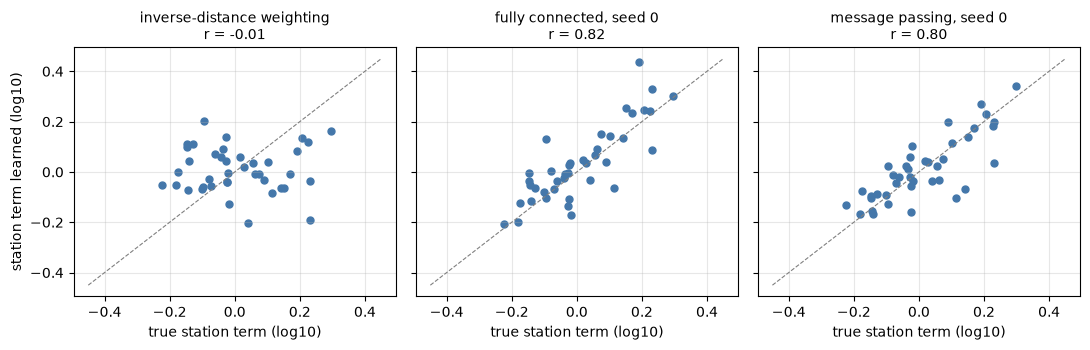

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True)
panels = [("inverse-distance weighting", baselines["inverse-distance weighting"]),
          ("fully connected, seed 0", results["fully connected"][0]["pred"]),
          ("message passing, seed 0", results["message passing"][0]["pred"])]
for ax, (name, p) in zip(axes, panels):
    est = site_term_estimate(p)
    ax.scatter(st_true, est, s=25, color="#4477AA")
    ax.plot([-0.45, 0.45], [-0.45, 0.45], color="gray", lw=0.8, ls="--")
    ax.set_title(f"{name}\nr = {np.corrcoef(est, st_true)[0, 1]:.2f}", fontsize=10)
    ax.set_xlabel("true station term (log10)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("station term learned (log10)")
plt.tight_layout()
plt.show()

The gain over IDW comes from the stations, not from the geometry of the shaking. IDW gives every station the average of its neighbors, so a station on soft ground is always under-predicted. The fully connected and message-passing networks learned each station's term from the 565 training earthquakes. The fully connected network learns it from the station's position in its input list; the message-passing network has no coordinates and no station numbers, so it learns it from the pattern of distances and offsets to its neighbors, which is different at every station. Section 11 shows the cost of that trick.

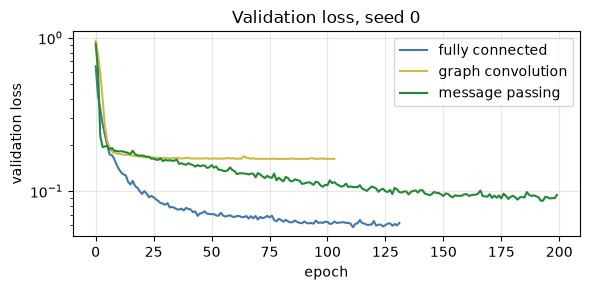

In [21]:
plt.figure(figsize=(6, 3))
for name, color in [("fully connected", "#4477AA"), ("graph convolution", "#CCBB44"), ("message passing", "#228833")]:
    plt.plot(results[name][0]["history"]["validation"], color=color, label=name)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Validation loss, seed 0")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Test 1: shuffle the station order

The order in which we list the stations is a choice of bookkeeping, not a property of the Earth. A method for a station network should give the same prediction at each station whatever the order. We draw a new order of the 40 stations, reorder the test inputs, rebuild the graph from the reordered coordinates, and predict again with the trained networks.

### Your turn (3): the permutation test

For the message-passing network of seed 0, build the reordered inputs `X_perm` and graph `g_perm`, predict, and compute the largest absolute change of any prediction compared with the original predictions put in the same order (`mp["pred"][:, perm]`).

Hint: `X_te[:, perm, :]`, `build_graph(xy[old][perm])`, `predict(model, X, g)` and `np.abs(...).max()`. Three lines.

In [22]:
perm = np.random.default_rng(99).permutation(40)   # a new order of the 40 stations
mp = results["message passing"][0]                  # message passing, seed 0

X_perm = None   # your code: test inputs, stations in the new order
g_perm = None   # your code: the graph built from the coordinates in the new order
change = None   # your code: largest |new prediction - original prediction in the new order|

*Answer below (click to open it).*

In [23]:
X_perm = X_te[:, perm, :]
g_perm = build_graph(xy[old][perm])
change = np.abs(predict(mp["model"], X_perm, g_perm) - mp["pred"][:, perm]).max()
print(f"largest change of a message-passing prediction: {change:.1e} (log10 PGA)")

largest change of a message-passing prediction: 4.8e-07 (log10 PGA)


The same test for every network and every seed:

In [24]:
rows = []
for name, runs in results.items():
    g = g_perm if name != "fully connected" else None
    preds = [predict(r["model"], X_perm, g) for r in runs]
    rows.append({"model": name, "test MAE, original order": np.mean([r["mae"] for r in runs]),
                 "test MAE, shuffled order": np.mean([mae(p, y_te[:, perm], m_te[:, perm]) for p in preds]),
                 "largest change of a prediction": max(np.abs(p - r["pred"][:, perm]).max() for p, r in zip(preds, runs))})
table1 = pd.DataFrame(rows).set_index("model")
table1["largest change of a prediction"] = table1["largest change of a prediction"].map("{:.1e}".format)
table1.round(3)

,"test MAE, original order","test MAE, shuffled order",largest change of a prediction
model,,,
fully connected,0.136,0.373,2.0e+00
graph convolution,0.187,0.187,4.8e-07
message passing,0.137,0.137,6.0e-07


The fully connected network falls from 0.136 to 0.373, worse than the mean of recorded stations (0.306): it reads each input by its position, and the positions now hold other stations. Its predictions change by up to 2.0 in log10 PGA, a factor of 93. The two graph networks give the same predictions to within 6e-07, the rounding of 32-bit numbers: a station's prediction depends on its own numbers and on its neighbors, found through the graph, not on its place in a list. This property is called **permutation equivariance**. In a real network, the fully connected network would have to be retrained whenever the station list is reordered, a station is renamed, or an instrument is swapped.

## 11. Test 2: ten new stations

Networks grow. Here the 10 stations held out since section 2 are "installed" after training. We build the graph of all 50 stations, hide the 10 new stations in every test data sample (they have no recording history the networks could know), keep the same hidden stations among the 40 old ones, and predict with the networks trained on 40 stations. The fully connected network cannot run: its first layer expects exactly 80 inputs.

In [25]:
g_all = build_graph(xy)                             # the grown network: 50 stations
m_all = np.zeros((len(te), 50), dtype=bool)
m_all[:, old] = m_te                                # same hidden stations among the old ones
m_all[:, new] = True                                # the new stations are always hidden
X_all, y_all = node_inputs(z[te], m_all), Y[te]
at_new = np.zeros_like(m_all)
at_new[:, new] = True
at_old = np.zeros_like(m_all)
at_old[:, old] = m_te

rows = [{"method": "floor: station term + noise left", "new stations": np.abs(station_plus_noise[te])[at_new].mean()},
        {"method": "floor: noise only left", "new stations": np.abs(noise_only[te])[at_new].mean()}]
for name, f in [("mean of recorded stations", lambda: mean_of_recorded(y_all, m_all)),
                ("inverse-distance weighting", lambda: idw(y_all, m_all, xy))]:
    p = f()
    rows.append({"method": name, "new stations": mae(p, y_all, at_new), "old stations": mae(p, y_all, at_old)})
preds_all = {}
for name in ("graph convolution", "message passing"):
    preds_all[name] = [predict(r["model"], X_all, g_all) for r in results[name]]
    new_m = [mae(p, y_all, at_new) for p in preds_all[name]]
    old_m = [mae(p, y_all, at_old) for p in preds_all[name]]
    rows.append({"method": name, "new stations": np.mean(new_m), "± std (new)": np.std(new_m, ddof=1),
                 "old stations": np.mean(old_m), "± std (old)": np.std(old_m, ddof=1),
                 "old stations, 40-station network": np.mean([r["mae"] for r in results[name]])})
rows.append({"method": "fully connected: cannot run"})
print("test MAE (log10 PGA) at the 10 new stations and at the hidden old stations of the grown network")
pd.DataFrame(rows).set_index("method").round(3)

test MAE (log10 PGA) at the 10 new stations and at the hidden old stations of the grown network


,new stations,old stations,± std (new),± std (old),"old stations, 40-station network"
method,,,,,
floor: station term + noise left,0.193,NaN,NaN,NaN,NaN
floor: noise only left,0.081,NaN,NaN,NaN,NaN
mean of recorded stations,0.319,0.306,NaN,NaN,NaN
inverse-distance weighting,0.200,0.182,NaN,NaN,NaN
graph convolution,0.199,0.188,0.000,0.001,0.187
message passing,0.233,0.196,0.008,0.020,0.137
fully connected: cannot run,NaN,NaN,NaN,NaN,NaN


In [26]:
applied = (preds_all["message passing"][0] - y_all + station_plus_noise[te])[:, new].mean(0)
print("true station terms of the new stations:      ", station_term[new].round(2))
print("station terms applied by message passing (seed 0):", applied.round(2))
print(f"standard deviation of the applied terms: {applied.std(ddof=1):.2f}")
print(f"correlation over the 10 new stations: r = {np.corrcoef(applied, station_term[new])[0, 1]:.2f}")
print(f"rms of the true station terms: new {np.sqrt((station_term[new] ** 2).mean()):.3f}, "
      f"old {np.sqrt((station_term[old] ** 2).mean()):.3f}")

true station terms of the new stations:       [ 0.06 -0.28  0.2  -0.29 -0.25 -0.13 -0.02  0.09  0.2   0.25]
station terms applied by message passing (seed 0): [ 0.27  0.22  0.17  0.04  0.02 -0.18  0.11 -0.06  0.29  0.11]
standard deviation of the applied terms: 0.15
correlation over the 10 new stations: r = 0.33
rms of the true station terms: new 0.200, old 0.133


The graph networks run on the grown network, which the fully connected network cannot do. But at the new stations no learned network improves on IDW by a useful margin:

- **IDW is close to the floor.** IDW scores 0.200 at the new stations, against a floor of 0.193. The floor is higher here than on the old stations (0.138) because, with data seed 0, the new stations happen to sit on ground with larger station terms (rms 0.200 against 0.133).
- **The graph convolution** (0.199 ± 0.000) and IDW (0.200) differ by 0.001 in log10 PGA, a negligible difference: the graph convolution behaves like IDW, as it did on the old network.
- **Message passing is worse** (0.233 ± 0.008). It applies station terms at the new stations as if it knew them: their standard deviation is 0.15 in log10, but they correlate with the true terms at only r = 0.33 (10 stations, seed 0). Growing the network also hurts it at the old stations, from 0.137 to 0.196 ± 0.020: it recognized each old station by the distances and offsets to its neighbors, and the new stations changed those neighborhoods.

The reason is physical, not a matter of architecture: a station term is learned from a station's history of recordings, and a new station has none. Operational systems such as ShakeMap do not learn it from history either. They estimate site amplification from Vs30, the average shear-wave velocity of the top 30 m, mapped from geology and topography, so a new location gets a physically based term from its first day. A graph network could take Vs30 as a node feature; this synthetic data set has none.

## 12. Exercise (optional): train on random sub-networks

The message-passing network broke at the old stations when the network grew, because it had only ever seen one network. Train it instead on a different sub-network at every batch: remove a random set of up to 10 of the 40 stations, rebuild the graph from the remaining ones, and compute the loss on their hidden stations. Then rerun section 11. Does the error at the old stations of the grown network go down? At the new stations?

Hint: in `train`, replace the line that computes `loss` with a few lines that draw `keep = np.sort(rng.choice(40, 40 - n_drop, replace=False))`, build `build_graph(xy[old][keep])`, and index the batch with `[:, keep]`. Train only the graph networks this way; the fully connected network needs all 40 inputs.

```{admonition} Solution
:class: dropdown

Inside the batch loop of `train`:

    if g is not None:                                   # graph networks only
        n_drop = rng.integers(0, 11)                    # remove 0 to 10 stations
        keep = np.sort(rng.choice(40, 40 - n_drop, replace=False))
        loss = masked_mse(model(X[idx][:, keep], build_graph(xy[old][keep])),
                          z_tr[idx][:, keep], M[idx][:, keep])
    else:
        loss = masked_mse(model(X[idx], g), z_tr[idx], M[idx])

A run of this change (`pixi run python book/slides/2026/figscripts/lec23b_gnn_numbers.py --subnetworks`, a copy of this notebook's code with the lines above, seeds 0, 1 and 2) gave, for message passing:

| | trained on the full network | trained on sub-networks |
|---|---|---|
| test MAE, 40-station network | 0.137 | 0.149 |
| MAE at the 10 new stations | 0.233 | 0.220 |
| MAE at hidden old stations, grown network | 0.196 | 0.168 |

IDW scores 0.200 at the new stations and 0.182 at the hidden old stations of the grown network. Training on sub-networks costs accuracy on the fixed network, brings the old stations of the grown network below IDW, and leaves the new stations above it.

Training on many sub-networks teaches the network that neighborhoods change, so it leans less on recognizing each station by its neighbors. It cannot create station terms that the data never showed it, so the new stations do not improve on IDW.
```

## 13. Summary

| | fully connected | graph convolution | message passing | IDW (no training) |
|---|---|---|---|---|
| reads the stations as | a fixed list of 40 | a graph: normalized average over neighbors | a graph with distances and directions on the edges | distances |
| weights | 32,040 | 1,185 | 4,577 | 0 |
| test MAE, 40 stations (log10 PGA) | 0.136 | 0.187 | 0.137 | 0.182 |
| learned station terms (site-term r) | yes (0.83) | no (0.03) | yes (0.80) | no (-0.01) |
| test 1: station order shuffled | breaks (0.373) | unchanged | unchanged | unchanged |
| test 2: MAE at 10 new stations (floor 0.193) | cannot run | 0.199 | 0.233 | 0.200 |
| geoscience use | a fixed network that never changes | smoothing over irregular stations | station networks, meshes (GraphCast) | first baseline for any map |

- A station network is a **graph**: stations are nodes, edges join nearby stations, and the adjacency matrix and its normalized form $\hat A$ say who averages with whom.
- A **graph convolution** applies one weight matrix at every station and averages over neighbors. A **message-passing** layer lets each neighbor send a message that depends on the edge (distance and direction), averages the messages, and updates the station.
- Graph networks are **independent of station order** and **run on a network that grows**. The fully connected network is neither.
- On a fixed network, the fully connected network and message passing tie, and both beat IDW by learning **station terms**. At new stations, no learned network improves on IDW by a useful margin: station terms come from history or from physics (Vs30), not from the architecture.
- Rank every network against interpolation and against floors from the known truth before trusting the graph.

The training loop, early stopping, seeds and the leaderboard of this notebook are those of the training block, [4.7](mlgeo_4.7_ModelTraining.ipynb).

## Reflect on this notebook

As for every assignment in this course ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)), a few sentences each:

1. **What did you learn from this exercise?** Name the scientific or technical idea, with one example from your own work in this notebook.
2. **What did you learn from interacting with agents or chatbots?** Say what you asked, what the tool got right, what it got wrong, and how you found out.
3. **What would you suggest to improve this notebook so it meets its learning goals?** Be specific.

## References

- Bloemheuvel, S., van den Hoogen, J., Jozinović, D., Michelini, A., & Atzmueller, M. (2023). Graph neural networks for multivariate time series regression with application to seismic data. *International Journal of Data Science and Analytics*, 16(3), 317–332. https://doi.org/10.1007/s41060-022-00349-6
- Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O., & Dahl, G. E. (2017). Neural message passing for quantum chemistry. *Proceedings of the 34th International Conference on Machine Learning*, PMLR 70, 1263–1272. https://proceedings.mlr.press/v70/gilmer17a.html
- Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *International Conference on Learning Representations*. https://arxiv.org/abs/1609.02907
- Kirschstein, N., & Sun, Y. (2024). The merit of river network topology for neural flood forecasting. *Proceedings of the 41st International Conference on Machine Learning*, PMLR 235, 24713–24725. https://proceedings.mlr.press/v235/kirschstein24a.html
- Lam, R., Sanchez-Gonzalez, A., Willson, M., et al. (2023). Learning skillful medium-range global weather forecasting. *Science*, 382(6677), 1416–1421. https://doi.org/10.1126/science.adi2336
- Scarselli, F., Gori, M., Tsoi, A. C., Hagenbuchner, M., & Monfardini, G. (2009). The graph neural network model. *IEEE Transactions on Neural Networks*, 20(1), 61–80. https://doi.org/10.1109/TNN.2008.2005605
- Schill, C., & Bradley, B. A. (2026). Post-event ground motion estimation using graph neural networks. *Earthquake Spectra*, 42(3), e70094. https://doi.org/10.1002/esp4.70094
- Trappolini, D., Oliveti, I., Faenza, L., Jozinović, D., & Michelini, A. (2025). Masked graph neural network for rapid ground motion prediction in Italy. *Seismica*, 4(2). https://doi.org/10.26443/seismica.v4i2.1655
- van den Ende, M. P. A., & Ampuero, J.-P. (2020). Automated seismic source characterization using deep graph neural networks. *Geophysical Research Letters*, 47(17), e2020GL088690. https://doi.org/10.1029/2020GL088690